# Google Colab – Khảo sát và kiểm tra chất lượng dữ liệu

**Mục tiêu notebook**
- Khảo sát 4 bảng dữ liệu: `ecom_sales`, `customer`, `product`, `region`.
- Kiểm tra cấu trúc, dữ liệu thiếu, trùng lặp, giá trị bất thường và tính toàn vẹn tham chiếu.
- Minh họa chất lượng dữ liệu bằng bảng tổng hợp và biểu đồ.
- Tạo danh sách các dòng ngoại lệ cần đối chiếu.
- Đối chiếu kết quả trước xử lý với **bảng Silver** sau khi nhóm đã xây dựng Silver.

> Nguyên tắc: notebook chỉ kiểm tra và minh họa. Không tự đoán để sửa các mã bất thường như `RRR0001 -> R0001` hoặc `PPP... -> P...` khi chưa có bằng chứng từ nguồn.

## Step 1 – Chuẩn bị môi trường

Notebook sử dụng `pandas` để xử lý bảng và `matplotlib` để minh họa.  
Trong Google Colab, các thư viện này đã có sẵn.

In [2]:
import os
import zipfile
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

print("Đã nạp thư viện.")

Đã nạp thư viện.


## Step 2 – Tải và giải nén dữ liệu

Cách dùng trên Colab:
1. Đổi tên file ZIP thành `Dataset.zip` hoặc sửa biến `ZIP_PATH`.
2. Upload file vào Colab.
3. Chạy cell bên dưới.

Nếu file nằm trong Google Drive, có thể thay `ZIP_PATH` bằng đường dẫn Drive tương ứng.

In [3]:
import os
import zipfile

ZIP_PATH = "/content/Dataset-20261019T140825Z-1-001.zip"
EXTRACT_DIR = "/content/ecommerce_dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Đã giải nén dữ liệu thành công!")

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        print(os.path.join(root, file))

Đã giải nén dữ liệu thành công!
/content/ecommerce_dataset/Dataset/product.csv
/content/ecommerce_dataset/Dataset/customer.csv
/content/ecommerce_dataset/Dataset/ecom_sales.csv
/content/ecommerce_dataset/Dataset/region.csv


## Step 3 – Đọc 4 bảng dữ liệu

Notebook tự tìm các file CSV bên trong thư mục đã giải nén, nên không phụ thuộc việc ZIP có thêm thư mục con `Dataset/` hay không.

In [4]:
def find_csv(root, filename):
    matches = list(Path(root).rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Không tìm thấy {filename} trong {root}")
    return str(matches[0])

sales_path = find_csv(EXTRACT_DIR, "ecom_sales.csv")
customer_path = find_csv(EXTRACT_DIR, "customer.csv")
product_path = find_csv(EXTRACT_DIR, "product.csv")
region_path = find_csv(EXTRACT_DIR, "region.csv")

sales = pd.read_csv(sales_path)
customer = pd.read_csv(customer_path)
product = pd.read_csv(product_path)
region = pd.read_csv(region_path)

tables = {
    "ecom_sales": sales,
    "customer": customer,
    "product": product,
    "region": region
}

for name, df in tables.items():
    print(f"{name:12s}: {df.shape[0]:,} dòng x {df.shape[1]} cột")

ecom_sales  : 51,290 dòng x 11 cột
customer    : 17,415 dòng x 11 cột
product     : 28,356 dòng x 4 cột
region      : 3,828 dòng x 8 cột


## Step 4 – Khảo sát cấu trúc và kiểu dữ liệu

Mục đích:
- Xem số dòng, số cột.
- Kiểm tra tên cột và kiểu dữ liệu.
- Xem nhanh một vài dòng đầu để phát hiện vấn đề định dạng.

In [5]:
for name, df in tables.items():
    print("\n" + "="*80)
    print(name.upper())
    print("="*80)
    print("Kích thước:", df.shape)
    print("\nKiểu dữ liệu:")
    display(df.dtypes.to_frame("dtype"))
    print("\n5 dòng đầu:")
    display(df.head())


ECOM_SALES
Kích thước: (51290, 11)

Kiểu dữ liệu:


,dtype
row_id,int64
order_id,object
order_date,object
customer_id,object
segment,object
region_code,object
product_code,object
quantity,int64
sales,float64
discount,float64



5 dòng đầu:


,row_id,order_id,order_date,customer_id,segment,region_code,product_code,quantity,sales,discount,profit
0,1,MX-2015-SC2057582-42279,2023-10-02,SC-2057582,Consumer,R2140,P000409,3,48.0,0.0,19.2
1,2,MX-2013-KW1657028-41562,2021-10-15,KW-1657028,Consumer,R0816,P000147,8,48.0,0.0,7.2
2,3,MX-2013-KW1657028-41562,2021-10-15,KW-1657028,Consumer,R0816,P000395,2,16.0,0.0,8.0
3,4,MX-2013-KW1657028-41562,2021-10-15,KW-1657028,Consumer,R0816,P002140,4,28.0,0.0,14.0
4,5,MX-2013-KW1657028-41562,2021-10-15,KW-1657028,Consumer,R0816,P002828,2,20.0,0.0,10.0



CUSTOMER
Kích thước: (17415, 11)

Kiểu dữ liệu:


,dtype
customer_id,object
first_name,object
last_name,object
birth_date,object
marital_status,object
gender,object
email_address,object
annual_income,int64
education_level,object
occupation,object


... (7 outputs left out)

,dtype
region_code,object
city,object
state,object
country,object
country_latitude,float64
country_longitude,float64
region,object
market,object



5 dòng đầu:


,region_code,city,state,country,country_latitude,country_longitude,region,market
0,R0001,Jalalabad,Nangarhar,Afghanistan,33.939110,67.709953,Southern Asia,Asia Pacific
1,R0002,Herat,Hirat,Afghanistan,33.939110,67.709953,Southern Asia,Asia Pacific
2,R0003,Kabul,Kabul,Afghanistan,33.939110,67.709953,Southern Asia,Asia Pacific
3,R0004,Kandahar,Kandahar,Afghanistan,33.939110,67.709953,Southern Asia,Asia Pacific
4,R0005,Elbasan,Elbasan,Albania,41.153332,20.168331,Southern Europe,Europe


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## Step 5 – Chuẩn hóa kiểu dữ liệu phục vụ kiểm tra

Bước này **không thay đổi dữ liệu gốc**; chỉ tạo bản sao để các phép kiểm tra ngày và số được thực hiện chính xác.

In [7]:
sales_check = sales.copy()
customer_check = customer.copy()

sales_check["order_date"] = pd.to_datetime(sales_check["order_date"], errors="coerce")
customer_check["birth_date"] = pd.to_datetime(customer_check["birth_date"], errors="coerce")

for col in ["quantity", "sales", "discount", "profit"]:
    sales_check[col] = pd.to_numeric(sales_check[col], errors="coerce")

customer_check["annual_income"] = pd.to_numeric(
    customer_check["annual_income"], errors="coerce"
)

print("Đã tạo các bảng *_check để phục vụ kiểm tra.")

Đã tạo các bảng *_check để phục vụ kiểm tra.


## Step 6 – Kiểm tra dữ liệu thiếu (Completeness)

Ta đếm số giá trị `NULL/NaN` ở từng cột và tính tỷ lệ thiếu.  
Đây là một trong các chỉ tiêu cơ bản để đánh giá chất lượng dữ liệu.

In [8]:
missing_summary = []

for name, df in {
    "ecom_sales": sales_check,
    "customer": customer_check,
    "product": product,
    "region": region
}.items():
    temp = pd.DataFrame({
        "table": name,
        "column": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_pct": (df.isna().mean().values * 100).round(4)
    })
    missing_summary.append(temp)

missing_summary = pd.concat(missing_summary, ignore_index=True)
display(missing_summary[missing_summary["missing_count"] > 0])

print("Tổng số ô thiếu:", int(missing_summary["missing_count"].sum()))

,table,column,missing_count,missing_pct
16,customer,gender,124,0.712


Tổng số ô thiếu: 124


### Minh họa tỷ lệ thiếu dữ liệu

Biểu đồ chỉ hiển thị các cột có dữ liệu thiếu.

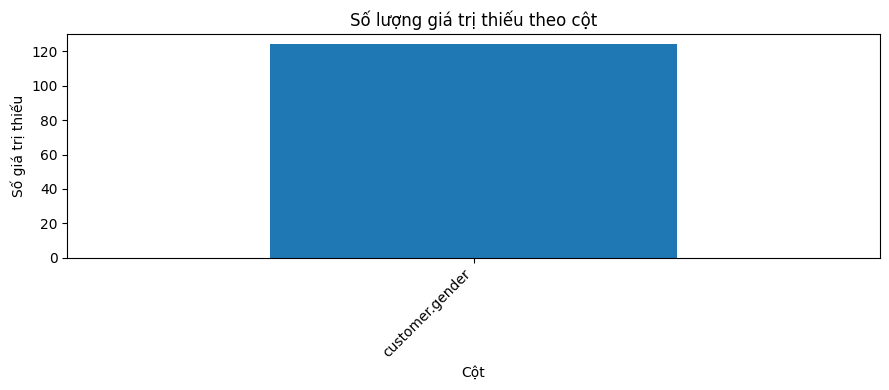

In [9]:
missing_plot = missing_summary[missing_summary["missing_count"] > 0].copy()
missing_plot["label"] = missing_plot["table"] + "." + missing_plot["column"]

if len(missing_plot) > 0:
    ax = missing_plot.set_index("label")["missing_count"].plot(kind="bar", figsize=(9, 4))
    ax.set_title("Số lượng giá trị thiếu theo cột")
    ax.set_xlabel("Cột")
    ax.set_ylabel("Số giá trị thiếu")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Không có giá trị thiếu.")

## Step 7 – Kiểm tra khóa và bản ghi trùng lặp

Các khóa được kiểm tra:
- `ecom_sales.row_id`
- `customer.customer_id`
- `product.product_code`
- `region.region_code`

Lưu ý: `order_id` lặp **không đồng nghĩa là lỗi**, vì một đơn hàng có thể chứa nhiều dòng sản phẩm.

In [10]:
key_checks = []

for table_name, df, key in [
    ("ecom_sales", sales_check, "row_id"),
    ("customer", customer_check, "customer_id"),
    ("product", product, "product_code"),
    ("region", region, "region_code"),
]:
    key_checks.append({
        "table": table_name,
        "key": key,
        "total_rows": len(df),
        "distinct_key": df[key].nunique(dropna=True),
        "null_key": int(df[key].isna().sum()),
        "duplicate_rows_by_key": int(df.duplicated(subset=[key], keep=False).sum())
    })

key_checks = pd.DataFrame(key_checks)
display(key_checks)

print("Số order_id phân biệt:", sales_check["order_id"].nunique())
print("Tổng số dòng ecom_sales:", len(sales_check))

,table,key,total_rows,distinct_key,null_key,duplicate_rows_by_key
0,ecom_sales,row_id,51290,51290,0,0
1,customer,customer_id,17415,17415,0,0
2,product,product_code,28356,28356,0,0
3,region,region_code,3828,3828,0,0


Số order_id phân biệt: 25728
Tổng số dòng ecom_sales: 51290


## Step 8 – Kiểm tra giá trị bất thường trong `ecom_sales`

Các quy tắc khảo sát:
- `quantity <= 0`
- `sales < 0`
- `discount < 0`
- `discount > 1`
- `profit < 0`
- `order_date` nằm trong tương lai

**Chú ý:** `profit < 0` có thể là giao dịch lỗ, không mặc định là dữ liệu sai.

In [12]:
today = pd.Timestamp.today().normalize()

abnormal_summary = pd.DataFrame({
    "check": [
        "quantity <= 0",
        "sales < 0",
        "discount < 0",
        "discount > 1",
        "profit < 0",
        "order_date trong tương lai"
    ],
    "count": [
        int((sales_check["quantity"] <= 0).sum()),
        int((sales_check["sales"] < 0).sum()),
        int((sales_check["discount"] < 0).sum()),
        int((sales_check["discount"] > 1).sum()),
        int((sales_check["profit"] < 0).sum()),
        int((sales_check["order_date"] > today).sum())
    ]
})

display(abnormal_summary)

range_summary = pd.DataFrame({
    "column": ["quantity", "sales", "discount", "profit"],
    "min": [
        sales_check["quantity"].min(),
        sales_check["sales"].min(),
        sales_check["discount"].min(),
        sales_check["profit"].min()
    ],
    "max": [
        sales_check["quantity"].max(),
        sales_check["sales"].max(),
        sales_check["discount"].max(),
        sales_check["profit"].max()
    ]
})
display(range_summary)

,check,count
0,quantity <= 0,0
1,sales < 0,0
2,discount < 0,0
3,discount > 1,0
4,profit < 0,11041
5,order_date trong tương lai,0


,column,min,max
0,quantity,1.0,20.00
1,sales,2.0,3940.00
2,discount,0.0,0.85
3,profit,-1746.0,1820.00


### Minh họa một số đặc điểm chất lượng dữ liệu

- Biểu đồ 1: số dòng vi phạm từng quy tắc.
- Biểu đồ 2: phân bố `profit` để thấy phần lợi nhuận âm không phải chỉ là một vài giá trị đơn lẻ.

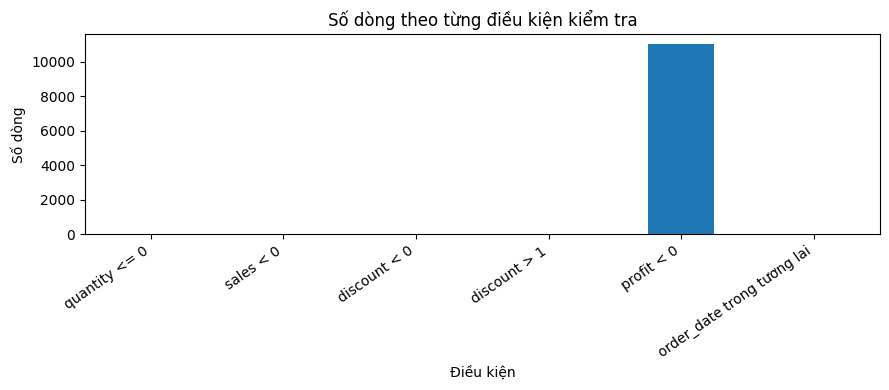

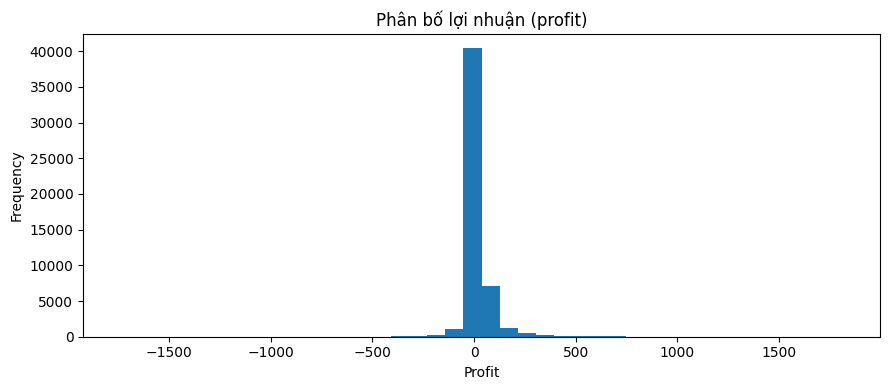

In [13]:
ax = abnormal_summary.set_index("check")["count"].plot(kind="bar", figsize=(9, 4))
ax.set_title("Số dòng theo từng điều kiện kiểm tra")
ax.set_xlabel("Điều kiện")
ax.set_ylabel("Số dòng")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

ax = sales_check["profit"].plot(kind="hist", bins=40, figsize=(9, 4))
ax.set_title("Phân bố lợi nhuận (profit)")
ax.set_xlabel("Profit")
plt.tight_layout()
plt.show()

## Step 9 – Kiểm tra riêng các bảng danh mục

Ta kiểm tra tổng số dòng, số khóa phân biệt và số lượng NULL ở các trường quan trọng.

In [14]:
dimension_summary = []

for table_name, df, key, important_cols in [
    ("customer", customer_check, "customer_id",
     ["customer_id", "first_name", "last_name", "birth_date", "gender", "email_address", "annual_income"]),
    ("product", product, "product_code",
     ["product_code", "product", "category", "subcategory"]),
    ("region", region, "region_code",
     ["region_code", "city", "state", "country", "region", "market"])
]:
    row = {
        "table": table_name,
        "total_rows": len(df),
        "distinct_key": df[key].nunique(dropna=True)
    }
    for col in important_cols:
        row[f"null_{col}"] = int(df[col].isna().sum())
    dimension_summary.append(row)

dimension_summary = pd.DataFrame(dimension_summary)
display(dimension_summary)

,table,total_rows,distinct_key,null_customer_id,null_first_name,null_last_name,null_birth_date,null_gender,null_email_address,null_annual_income,null_product_code,null_product,null_category,null_subcategory,null_region_code,null_city,null_state,null_country,null_region,null_market
0,customer,17415,17415,0.0,0.0,0.0,0.0,124.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,product,28356,28356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,region,3828,3828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0


## Step 10 – Kiểm tra tính toàn vẹn tham chiếu

Đối chiếu các khóa trong `ecom_sales` với bảng danh mục:
- `customer_id` ↔ `customer.customer_id`
- `product_code` ↔ `product.product_code`
- `region_code` ↔ `region.region_code`

Mục tiêu là tìm các giao dịch tham chiếu tới mã không tồn tại trong bảng danh mục.

In [15]:
customer_keys = set(customer["customer_id"].dropna())
product_keys = set(product["product_code"].dropna())
region_keys = set(region["region_code"].dropna())

sales_ref = sales.copy()

sales_ref["customer_match"] = sales_ref["customer_id"].isin(customer_keys)
sales_ref["product_match"] = sales_ref["product_code"].isin(product_keys)
sales_ref["region_match"] = sales_ref["region_code"].isin(region_keys)

ref_summary = pd.DataFrame({
    "check": [
        "Không khớp customer",
        "Không khớp product",
        "Không khớp region"
    ],
    "count": [
        int((~sales_ref["customer_match"]).sum()),
        int((~sales_ref["product_match"]).sum()),
        int((~sales_ref["region_match"]).sum())
    ]
})

display(ref_summary)

,check,count
0,Không khớp customer,0
1,Không khớp product,2
2,Không khớp region,2


## Step 11 – Lập danh sách dòng ngoại lệ

Không tự sửa mã. Các dòng không khớp được đưa vào danh sách để nhóm đối chiếu lại với dữ liệu nguồn hoặc danh mục chuẩn.

In [16]:
exceptions = sales_ref[
    (~sales_ref["customer_match"]) |
    (~sales_ref["product_match"]) |
    (~sales_ref["region_match"])
].copy()

exceptions["customer_check"] = np.where(
    exceptions["customer_match"],
    "Khớp customer",
    "Không khớp customer"
)

exceptions["product_check"] = np.where(
    exceptions["product_match"],
    "Khớp product",
    "Không khớp product"
)

exceptions["region_check"] = np.where(
    exceptions["region_match"],
    "Khớp region",
    "Không khớp region"
)

exception_cols = [
    "row_id", "order_id", "customer_id",
    "product_code", "region_code",
    "customer_check", "product_check", "region_check"
]

display(
    exceptions[exception_cols].sort_values("row_id")
)

exceptions[exception_cols].sort_values("row_id").to_csv(
    "/content/dong_ngoai_le.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất file: /content/dong_ngoai_le.csv")

,row_id,order_id,customer_id,product_code,region_code,customer_check,product_check,region_check
25219,25220,IN-2012-TH211151-41003,TH-211151,PPP000010,RRR0001,Khớp customer,Không khớp product,Không khớp region
25220,25221,IN-2012-TH211151-41003,TH-211151,P000001,RRR0001,Khớp customer,Khớp product,Không khớp region
29463,29464,ID-2013-BD116051-41518,BD-116051,PPP000002,R0002,Khớp customer,Không khớp product,Khớp region


Đã xuất file: /content/dong_ngoai_le.csv


## Step 12 – Tổng hợp kết quả khảo sát dữ liệu thô

Với bộ dữ liệu hiện tại, kết quả kỳ vọng sau khi chạy notebook là:

- `ecom_sales`: **51.290 dòng**, `row_id` phân biệt **51.290**, `order_id` phân biệt **25.728**, `customer_id` phân biệt **17.415**.
- Không phát hiện NULL ở các cột giao dịch chính đã kiểm tra.
- Không phát hiện `quantity <= 0`, `sales < 0`, `discount < 0`, `discount > 1`.
- Có **11.041** dòng `profit < 0`; đây được xem là giao dịch lỗ cho đến khi có bằng chứng khác.
- `customer.gender` thiếu **124** giá trị.
- Có **2** dòng không khớp `product_code`.
- Có **2** dòng không khớp `region_code`.
- Không có dòng không khớp `customer_id`.
- Các ngoại lệ chính liên quan đến `PPP000010`, `PPP000002` và `RRR0001`.

In [18]:
raw_kpi = {
    "Tổng dòng ecom_sales": len(sales_check),
    "row_id phân biệt": sales_check["row_id"].nunique(),
    "order_id phân biệt": sales_check["order_id"].nunique(),
    "customer_id phân biệt": sales_check["customer_id"].nunique(),

    "NULL cột giao dịch chính": int(
        sales_check[
            ["row_id", "order_id", "order_date",
             "customer_id", "product_code",
             "quantity", "sales", "discount", "profit"]
        ].isna().sum().sum()
    ),

    "profit < 0": int((sales_check["profit"] < 0).sum()),
    "customer.gender NULL": int(customer_check["gender"].isna().sum()),
    "Không khớp customer": int((~sales_ref["customer_match"]).sum()),
    "Không khớp product": int((~sales_ref["product_match"]).sum()),
    "Không khớp region": int((~sales_ref["region_match"]).sum())
}

raw_kpi_df = pd.DataFrame({
    "Chỉ tiêu": list(raw_kpi.keys()),
    "Trước xử lý": list(raw_kpi.values())
})

display(raw_kpi_df)

,Chỉ tiêu,Trước xử lý
0,Tổng dòng ecom_sales,51290
1,row_id phân biệt,51290
2,order_id phân biệt,25728
3,customer_id phân biệt,17415
4,NULL cột giao dịch chính,0
5,profit < 0,11041
6,customer.gender NULL,124
7,Không khớp customer,0
8,Không khớp product,2
9,Không khớp region,2


In [19]:
import os

OUTPUT_DIR = "/content/ket_qua_khao_sat"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Xuất bảng KPI trước xử lý
raw_kpi_df.to_csv(
    f"{OUTPUT_DIR}/01_kpi_truoc_xu_ly.csv",
    index=False,
    encoding="utf-8-sig"
)

# Xuất thống kê dữ liệu thiếu
missing_summary.to_csv(
    f"{OUTPUT_DIR}/02_missing_values.csv",
    index=False,
    encoding="utf-8-sig"
)

# Xuất thống kê giá trị bất thường
abnormal_summary.to_csv(
    f"{OUTPUT_DIR}/03_abnormal_values.csv",
    index=False,
    encoding="utf-8-sig"
)

# Xuất thống kê khóa trùng
key_checks.to_csv(
    f"{OUTPUT_DIR}/04_duplicate_keys.csv",
    index=False,
    encoding="utf-8-sig"
)

# Xuất danh sách ngoại lệ
exceptions[exception_cols].to_csv(
    f"{OUTPUT_DIR}/05_exception_records.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất thành công 5 file kết quả khảo sát!")
print("Thư mục lưu:", OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))

Đã xuất thành công 5 file kết quả khảo sát!
Thư mục lưu: /content/ket_qua_khao_sat
['03_abnormal_values.csv', '04_duplicate_keys.csv', '01_kpi_truoc_xu_ly.csv', '02_missing_values.csv', '05_exception_records.csv']


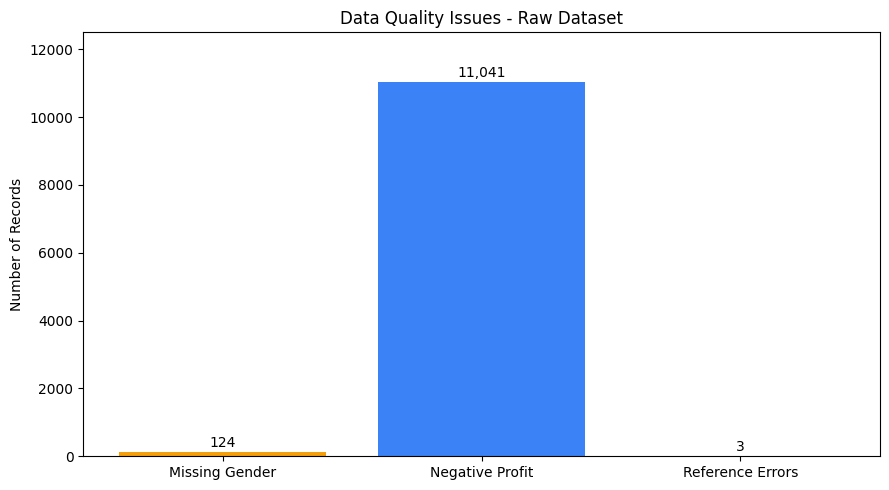

Đã lưu biểu đồ thành công!


In [20]:
import matplotlib.pyplot as plt

labels = [
    "Missing Gender",
    "Negative Profit",
    "Reference Errors"
]

values = [124, 11041, 3]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    values,
    color=["#F59E0B", "#3B82F6", "#EF4444"]
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 150,
        f"{int(height):,}",
        ha="center"
    )

plt.title("Data Quality Issues - Raw Dataset")
plt.ylabel("Number of Records")
plt.ylim(0, 12500)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/06_data_quality_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu biểu đồ thành công!")

# PHẦN B – Đối chiếu với bảng Silver

## Step 13 – Chuẩn bị dữ liệu Silver

**Khuyến nghị:** sau khi nhóm xây dựng các bảng Silver trong SQL Server/DBeaver, export các bảng Silver ra CSV và upload vào Colab.

Tên file mặc định notebook tìm:
- `/content/silver_ecom_sales.csv`
- `/content/silver_customer.csv`
- `/content/silver_product.csv`
- `/content/silver_region.csv`

Nếu nhóm dùng tên khác, chỉ cần sửa 4 biến đường dẫn.

In [ ]:
SILVER_SALES_PATH = "/content/silver_ecom_sales.csv"
SILVER_CUSTOMER_PATH = "/content/silver_customer.csv"
SILVER_PRODUCT_PATH = "/content/silver_product.csv"
SILVER_REGION_PATH = "/content/silver_region.csv"

silver_available = all(os.path.exists(p) for p in [
    SILVER_SALES_PATH, SILVER_CUSTOMER_PATH,
    SILVER_PRODUCT_PATH, SILVER_REGION_PATH
])

print("Đã đủ 4 file Silver?" , silver_available)

## Step 14 – Chạy lại cùng bộ kiểm tra trên Silver

Cell dưới đây chỉ chạy khi đủ 4 file Silver.  
Điều này giúp việc so sánh **trước – sau** dùng cùng một định nghĩa kiểm tra, tránh so sánh lệch tiêu chí.

In [ ]:
def profile_quality(sales_df, customer_df, product_df, region_df):
    s = sales_df.copy()
    c = customer_df.copy()

    s["order_date"] = pd.to_datetime(s["order_date"], errors="coerce")
    for col in ["quantity", "sales", "discount", "profit"]:
        s[col] = pd.to_numeric(s[col], errors="coerce")

    c["birth_date"] = pd.to_datetime(c["birth_date"], errors="coerce")

    customer_keys = set(customer_df["customer_id"].dropna())
    product_keys = set(product_df["product_code"].dropna())
    region_keys = set(region_df["region_code"].dropna())

    return {
        "Tổng dòng ecom_sales": len(s),
        "row_id phân biệt": s["row_id"].nunique(),
        "order_id phân biệt": s["order_id"].nunique(),
        "customer_id phân biệt": s["customer_id"].nunique(),
        "NULL cột giao dịch chính": int(
            s[
                ["row_id", "order_id", "order_date", "customer_id",
                 "product_code", "quantity", "sales", "discount", "profit"]
            ].isna().sum().sum()
        ),
        "profit < 0": int((s["profit"] < 0).sum()),
        "customer.gender NULL": int(c["gender"].isna().sum()),
        "Không khớp customer": int((~sales_df["customer_id"].isin(customer_keys)).sum()),
        "Không khớp product": int((~sales_df["product_code"].isin(product_keys)).sum()),
        "Không khớp region": int((~sales_df["region_code"].isin(region_keys)).sum())
    }

if silver_available:
    silver_sales = pd.read_csv(SILVER_SALES_PATH)
    silver_customer = pd.read_csv(SILVER_CUSTOMER_PATH)
    silver_product = pd.read_csv(SILVER_PRODUCT_PATH)
    silver_region = pd.read_csv(SILVER_REGION_PATH)

    silver_kpi = profile_quality(
        silver_sales, silver_customer, silver_product, silver_region
    )

    compare = pd.DataFrame({
        "Chỉ tiêu": list(raw_kpi.keys()),
        "Trước xử lý": [raw_kpi[k] for k in raw_kpi],
        "Silver": [silver_kpi[k] for k in raw_kpi]
    })
    compare["Chênh lệch"] = compare["Silver"] - compare["Trước xử lý"]
    display(compare)
else:
    print("Chưa có đủ file Silver.")
    print("Hãy export 4 bảng Silver từ DBeaver ra CSV, upload vào Colab rồi chạy lại Step 13-14.")

In [21]:
import shutil
from google.colab import files

# Nén toàn bộ kết quả khảo sát
zip_path = shutil.make_archive(
    "/content/Ket_qua_khao_sat_Colab",
    "zip",
    OUTPUT_DIR
)

print("Đã tạo file ZIP:", zip_path)

# Tải file ZIP về máy
files.download(zip_path)

Đã tạo file ZIP: /content/Ket_qua_khao_sat_Colab.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>